Customer Segmentation notebook started!
Libraries imported successfully!
Project root: c:\Users\VAISHNAVI V\Desktop\final internship poject\Customer_Intelligence_Predictive_Retention_Platform
Reports folder: c:\Users\VAISHNAVI V\Desktop\final internship poject\Customer_Intelligence_Predictive_Retention_Platform\reports
Segmentation CSV exists: True

CUSTOMER SEGMENTATION DATA
Rows: 7043
Columns: 22
Available columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'CustomerSegment']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerSegment
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,2
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,2
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,2



Customer records available for analysis: 7043
Segment labels: [np.int64(0), np.int64(1), np.int64(2)]

CUSTOMER COUNT BY SEGMENT


,Customer_Count
CustomerSegment,
0,2154
1,2200
2,2689


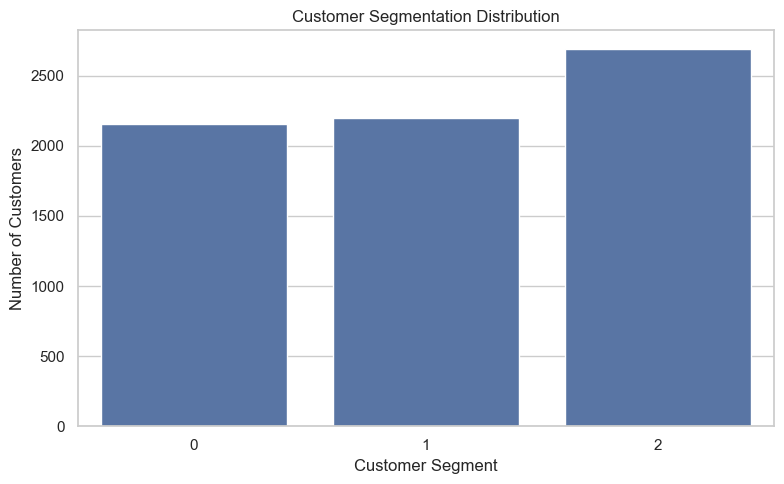


CHURN ANALYSIS BY CUSTOMER SEGMENT


,Total_Customers,Churned_Customers,Churn_Rate_Percent
CustomerSegment,,,
0,2154,265,12.30
1,2200,338,15.36
2,2689,1266,47.08


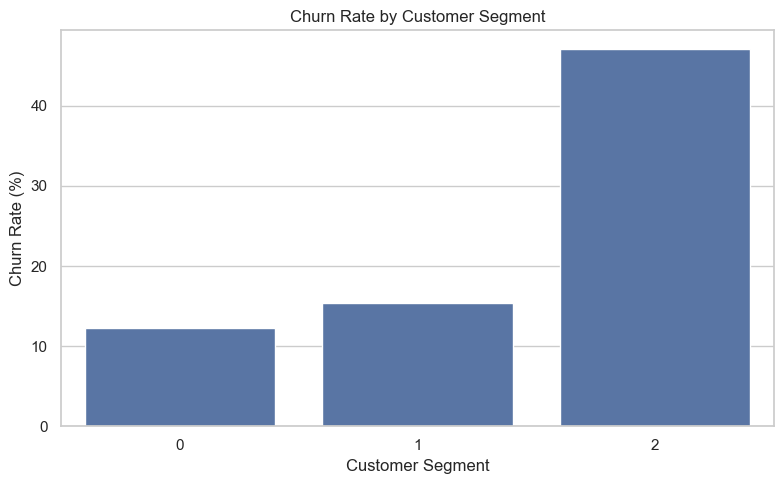


CUSTOMER SEGMENT PROFILES


,Customer_Count,Average_Tenure_Months,Average_Monthly_Charges,Average_Total_Charges,Churned_Customers,Churn_Rate_Percent
CustomerSegment,,,,,,
0,2154,29.50,26.57,809.42,265,12.30
1,2200,58.56,89.70,5246.13,338,15.36
2,2689,13.25,74.95,1030.57,1266,47.08


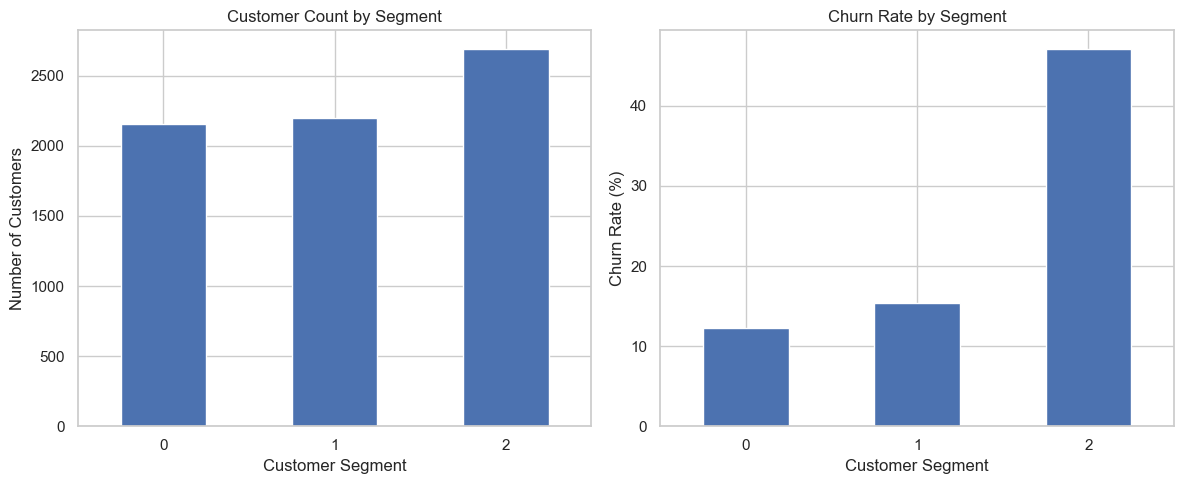


CUSTOMER SEGMENT BUSINESS SUMMARY


,Customer_Count,Average_Tenure_Months,Average_Monthly_Charges,Average_Total_Charges,Churned_Customers,Churn_Rate_Percent,Business_Insight
CustomerSegment,,,,,,,
0,2154,29.50,26.57,809.42,265,12.30,Lower observed churn - maintain engagement
1,2200,58.56,89.70,5246.13,338,15.36,Lower observed churn - maintain engagement
2,2689,13.25,74.95,1030.57,1266,47.08,High churn risk - prioritize retention



CUSTOMER SEGMENT VS CONTRACT TYPE


Contract,Month-to-month,One year,Two year,All
CustomerSegment,,,,
0,944,509,701,2154
1,583,681,936,2200
2,2348,283,58,2689
All,3875,1473,1695,7043



CHURN RATE BY SEGMENT AND CONTRACT


,CustomerSegment,Contract,Total_Customers,Churned_Customers,Churn_Rate_Percent
6,2,Month-to-month,2348,1227,52.26
3,1,Month-to-month,583,189,32.42
0,0,Month-to-month,944,239,25.32
4,1,One year,681,107,15.71
7,2,One year,283,39,13.78
5,1,Two year,936,42,4.49
1,0,One year,509,20,3.93
2,0,Two year,701,6,0.86
8,2,Two year,58,0,0.00



CONTRACT-WISE CHURN SUMMARY


,Total_Customers,Churned_Customers,Churn_Rate_Percent
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


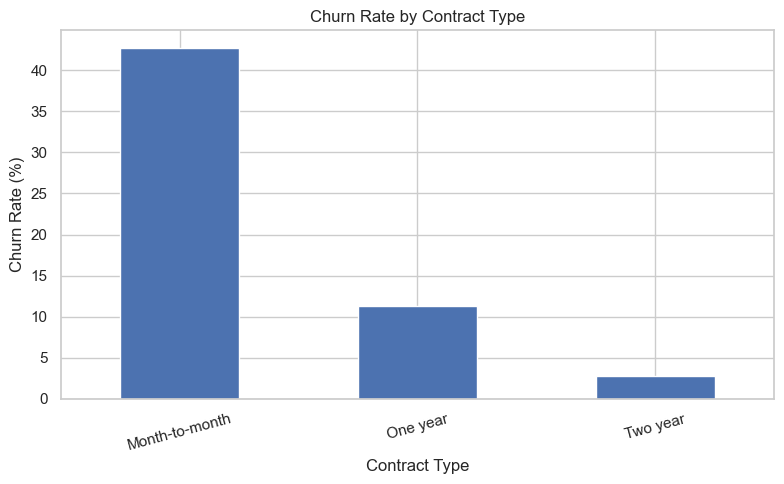


CHURN RATE (%) BY SEGMENT AND CONTRACT


Contract,Month-to-month,One year,Two year
CustomerSegment,,,
0,25.32,3.93,0.86
1,32.42,15.71,4.49
2,52.26,13.78,0.00


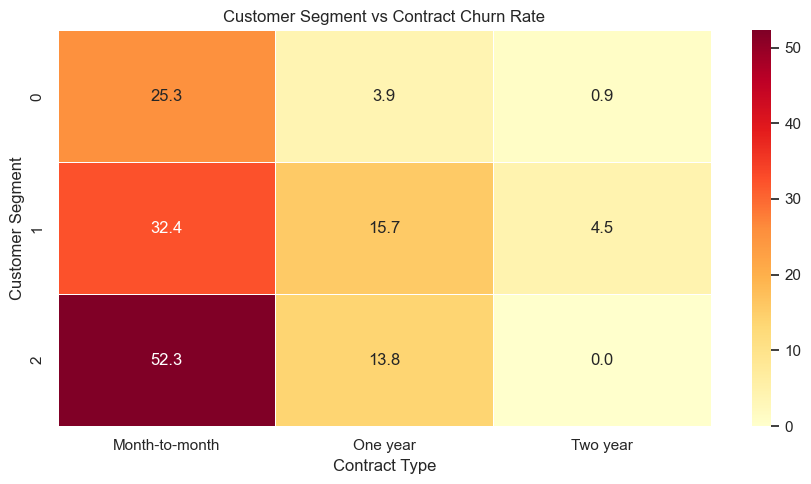


BUSINESS INSIGHTS

CUSTOMER SEGMENTATION - BUSINESS INSIGHTS REPORT

Total customers analysed: 7043
Number of customer segments: 3

Highest observed churn segment: 2
Highest churn rate: 47.08%

Lowest observed churn segment: 0
Lowest churn rate: 12.30%

CUSTOMER SEGMENT PROFILES
-------------------------
                 Customer_Count  Average_Tenure_Months  Average_Monthly_Charges  Average_Total_Charges  Churned_Customers  Churn_Rate_Percent
CustomerSegment                                                                                                                              
0                          2154                  29.50                    26.57                 809.42                265               12.30
1                          2200                  58.56                    89.70                5246.13                338               15.36
2                          2689                  13.25                    74.95                1030.57               1266    

In [ ]:

# Customer Intelligence & Predictive Retention Platform
# Notebook 03 — Customer Segmentation (Single-Cell Version)

from pathlib import Path
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Customer Segmentation notebook started!")
print("Libraries imported successfully!")

# --------------------------------------------------
# 1. FIND PROJECT ROOT AND LOAD SEGMENTATION DATA
# --------------------------------------------------

cwd = Path.cwd()

if (cwd / "reports").exists() and (cwd / "data").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "reports").exists() and (cwd.parent / "data").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Project root not found. Open the notebook from the project "
        "folder or its notebooks folder."
    )

REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

SEGMENTS_PATH = REPORTS_DIR / "customer_segments.csv"

print("Project root:", PROJECT_ROOT)
print("Reports folder:", REPORTS_DIR)
print("Segmentation CSV exists:", SEGMENTS_PATH.exists())

if not SEGMENTS_PATH.exists():
    raise FileNotFoundError(
        f"Customer segmentation file not found:\n{SEGMENTS_PATH}\n"
        "Please create customer_segments.csv before running this notebook."
    )

customer_segments = pd.read_csv(SEGMENTS_PATH)

print("\nCUSTOMER SEGMENTATION DATA")
print("=" * 50)
print("Rows:", customer_segments.shape[0])
print("Columns:", customer_segments.shape[1])
print("Available columns:", customer_segments.columns.tolist())
display(customer_segments.head())

# --------------------------------------------------
# 2. VALIDATE REQUIRED COLUMNS
# --------------------------------------------------

required_columns = [
    "customerID",
    "CustomerSegment",
    "Churn",
    "Contract",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

missing_columns = [
    col for col in required_columns
    if col not in customer_segments.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}\n"
        f"Available columns: {customer_segments.columns.tolist()}"
    )

for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    customer_segments[col] = pd.to_numeric(
        customer_segments[col], errors="coerce"
    )

customer_segments["CustomerSegment"] = pd.to_numeric(
    customer_segments["CustomerSegment"], errors="coerce"
)

customer_segments = customer_segments.dropna(
    subset=["CustomerSegment", "Churn", "customerID"]
).copy()

customer_segments["CustomerSegment"] = (
    customer_segments["CustomerSegment"].astype(int)
)

print("\nCustomer records available for analysis:", len(customer_segments))
print("Segment labels:", sorted(customer_segments["CustomerSegment"].unique()))

# --------------------------------------------------
# 3. CUSTOMER COUNT BY SEGMENT
# --------------------------------------------------

segment_counts = (
    customer_segments["CustomerSegment"]
    .value_counts()
    .sort_index()
)

print("\nCUSTOMER COUNT BY SEGMENT")
display(segment_counts.rename("Customer_Count").to_frame())

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    x=segment_counts.index.astype(str),
    y=segment_counts.values,
    ax=ax
)
ax.set_title("Customer Segmentation Distribution")
ax.set_xlabel("Customer Segment")
ax.set_ylabel("Number of Customers")
fig.tight_layout()
plt.show()
plt.close(fig)

# --------------------------------------------------
# 4. CHURN ANALYSIS BY SEGMENT
# --------------------------------------------------

churn_analysis = customer_segments.groupby("CustomerSegment").agg(
    Total_Customers=("customerID", "count"),
    Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
)

churn_analysis["Churn_Rate_Percent"] = (
    churn_analysis["Churned_Customers"]
    / churn_analysis["Total_Customers"] * 100
).round(2)

print("\nCHURN ANALYSIS BY CUSTOMER SEGMENT")
display(churn_analysis)

churn_path = REPORTS_DIR / "customer_segment_churn_analysis.csv"
churn_analysis.to_csv(churn_path, index=True)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    x=churn_analysis.index.astype(str),
    y=churn_analysis["Churn_Rate_Percent"],
    ax=ax
)
ax.set_title("Churn Rate by Customer Segment")
ax.set_xlabel("Customer Segment")
ax.set_ylabel("Churn Rate (%)")
fig.tight_layout()
fig.savefig(
    REPORTS_DIR / "customer_segment_churn.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# --------------------------------------------------
# 5. CUSTOMER SEGMENT PROFILES
# --------------------------------------------------

segment_profile = customer_segments.groupby("CustomerSegment").agg(
    Customer_Count=("customerID", "count"),
    Average_Tenure_Months=("tenure", "mean"),
    Average_Monthly_Charges=("MonthlyCharges", "mean"),
    Average_Total_Charges=("TotalCharges", "mean"),
    Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
).round(2)

segment_profile["Churn_Rate_Percent"] = (
    segment_profile["Churned_Customers"]
    / segment_profile["Customer_Count"] * 100
).round(2)

print("\nCUSTOMER SEGMENT PROFILES")
display(segment_profile)

profile_path = REPORTS_DIR / "customer_segment_profiles.csv"
segment_profile.to_csv(profile_path, index=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

segment_profile["Customer_Count"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Customer Count by Segment")
axes[0].set_xlabel("Customer Segment")
axes[0].set_ylabel("Number of Customers")
axes[0].tick_params(axis="x", rotation=0)

segment_profile["Churn_Rate_Percent"].plot(kind="bar", ax=axes[1])
axes[1].set_title("Churn Rate by Segment")
axes[1].set_xlabel("Customer Segment")
axes[1].set_ylabel("Churn Rate (%)")
axes[1].tick_params(axis="x", rotation=0)

fig.tight_layout()
fig.savefig(
    REPORTS_DIR / "customer_segment_profile.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# --------------------------------------------------
# 6. BUSINESS SUMMARY BY SEGMENT
# --------------------------------------------------

business_summary = segment_profile.copy()

def interpret_segment(row):
    if row["Churn_Rate_Percent"] >= 40:
        return "High churn risk - prioritize retention"
    elif row["Churn_Rate_Percent"] >= 20:
        return "Moderate churn risk - monitor customers"
    return "Lower observed churn - maintain engagement"

business_summary["Business_Insight"] = business_summary.apply(
    interpret_segment, axis=1
)

print("\nCUSTOMER SEGMENT BUSINESS SUMMARY")
display(business_summary)

business_summary_path = (
    REPORTS_DIR / "customer_segment_business_summary.csv"
)
business_summary.to_csv(business_summary_path, index=True)

# --------------------------------------------------
# 7. CONTRACT ANALYSIS
# --------------------------------------------------

contract_analysis = pd.crosstab(
    customer_segments["CustomerSegment"],
    customer_segments["Contract"],
    margins=True
)

print("\nCUSTOMER SEGMENT VS CONTRACT TYPE")
display(contract_analysis)

contract_churn = customer_segments.groupby(
    ["CustomerSegment", "Contract"]
).agg(
    Total_Customers=("customerID", "count"),
    Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
).reset_index()

contract_churn["Churn_Rate_Percent"] = (
    contract_churn["Churned_Customers"]
    / contract_churn["Total_Customers"] * 100
).round(2)

print("\nCHURN RATE BY SEGMENT AND CONTRACT")
display(contract_churn.sort_values("Churn_Rate_Percent", ascending=False))

contract_path = (
    REPORTS_DIR / "customer_segment_contract_analysis.csv"
)
contract_churn.to_csv(contract_path, index=False)

contract_summary = customer_segments.groupby("Contract").agg(
    Total_Customers=("customerID", "count"),
    Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
)

contract_summary["Churn_Rate_Percent"] = (
    contract_summary["Churned_Customers"]
    / contract_summary["Total_Customers"] * 100
).round(2)

print("\nCONTRACT-WISE CHURN SUMMARY")
display(contract_summary)

fig, ax = plt.subplots(figsize=(8, 5))
contract_summary["Churn_Rate_Percent"].plot(kind="bar", ax=ax)
ax.set_title("Churn Rate by Contract Type")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Churn Rate (%)")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(
    REPORTS_DIR / "contract_churn_chart.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# --------------------------------------------------
# 8. SEGMENT AND CONTRACT CHURN HEATMAP
# --------------------------------------------------

heatmap_data = customer_segments.pivot_table(
    index="CustomerSegment",
    columns="Contract",
    values="Churn",
    aggfunc=lambda x: (x == "Yes").mean() * 100
)

print("\nCHURN RATE (%) BY SEGMENT AND CONTRACT")
display(heatmap_data.round(2))

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    ax=ax
)
ax.set_title("Customer Segment vs Contract Churn Rate")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Customer Segment")
fig.tight_layout()
fig.savefig(
    REPORTS_DIR / "segment_contract_churn_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# --------------------------------------------------
# 9. BUSINESS INSIGHTS REPORT
# --------------------------------------------------

total_customers = len(customer_segments)
number_of_segments = customer_segments["CustomerSegment"].nunique()

highest_risk = segment_profile.loc[
    segment_profile["Churn_Rate_Percent"].idxmax()
]
lowest_risk = segment_profile.loc[
    segment_profile["Churn_Rate_Percent"].idxmin()
]

business_report = f"""
CUSTOMER SEGMENTATION - BUSINESS INSIGHTS REPORT
================================================

Total customers analysed: {total_customers}
Number of customer segments: {number_of_segments}

Highest observed churn segment: {highest_risk.name}
Highest churn rate: {highest_risk['Churn_Rate_Percent']:.2f}%

Lowest observed churn segment: {lowest_risk.name}
Lowest churn rate: {lowest_risk['Churn_Rate_Percent']:.2f}%

CUSTOMER SEGMENT PROFILES
-------------------------
{segment_profile.to_string()}

BUSINESS RECOMMENDATIONS
------------------------
1. Prioritize retention efforts for segments with higher observed churn.
2. Investigate onboarding, service issues, pricing and contract options.
3. Maintain engagement with lower-churn customer groups.
4. Review contract type and tenure patterns when planning interventions.
5. Measure retention campaign results before expanding the strategy.

LIMITATIONS
-----------
- Segment IDs are cluster labels, not predefined customer types.
- Observed churn patterns do not prove the causes of churn.
- Results describe this dataset and may not generalize to future customers.
- Recommendations should be tested against future customer data.
"""

insights_path = (
    REPORTS_DIR / "customer_segmentation_business_insights.txt"
)
insights_path.write_text(business_report.strip() + "\n", encoding="utf-8")

detailed_report = f"""
CUSTOMER INTELLIGENCE PLATFORM
CUSTOMER SEGMENTATION BUSINESS REPORT
=====================================

PROJECT OVERVIEW
----------------
This analysis profiles existing customer segments and their observed churn.

DATA SUMMARY
------------
Total customers analysed: {total_customers}
Number of segments: {number_of_segments}

SEGMENT PROFILES
----------------
{segment_profile.to_string()}

CONTRACT-WISE CHURN SUMMARY
---------------------------
{contract_summary.to_string()}

KEY FINDING
-----------
Highest observed churn segment: {highest_risk.name}
Churn rate: {highest_risk['Churn_Rate_Percent']:.2f}%

RECOMMENDATIONS
---------------
- Investigate the needs of higher-churn customer groups.
- Review contract options, tenure and service experience.
- Test targeted retention campaigns and measure their results.
- Monitor churn trends regularly.

LIMITATIONS
-----------
Segment labels are numeric identifiers. Correlation does not prove causation.
Results are based on the supplied dataset and require future validation.
"""

detailed_report_path = (
    REPORTS_DIR / "customer_segmentation_business_report.txt"
)
detailed_report_path.write_text(
    detailed_report.strip() + "\n",
    encoding="utf-8"
)

print("\nBUSINESS INSIGHTS")
print(business_report)

# --------------------------------------------------
# 10. FINAL REPORT AND CHART CHECK
# --------------------------------------------------

required_files = [
    "customer_segments.csv",
    "customer_segment_churn_analysis.csv",
    "customer_segment_profiles.csv",
    "customer_segment_business_summary.csv",
    "customer_segment_contract_analysis.csv",
    "customer_segmentation_business_insights.txt",
    "customer_segmentation_business_report.txt",
    "customer_segment_churn.png",
    "customer_segment_profile.png",
    "contract_churn_chart.png",
    "segment_contract_churn_heatmap.png"
]

print("\nFINAL CUSTOMER SEGMENTATION CHECKLIST")
print("=" * 55)

missing_files = []

for filename in required_files:
    file_path = REPORTS_DIR / filename
    if file_path.exists() and file_path.stat().st_size > 0:
        print("READY:", filename)
    else:
        print("MISSING:", filename)
        missing_files.append(filename)

print("\nTotal required files:", len(required_files))
print("Files ready:", len(required_files) - len(missing_files))
print("Files missing:", len(missing_files))

if missing_files:
    print("\nPlease review the missing files listed above.")
else:
    print("\nAll required segmentation reports are ready!")

print("\nNOTEBOOK 03 — CUSTOMER SEGMENTATION COMPLETED")
print("Reports folder:", REPORTS_DIR)
